# Proyecto integrador: métodos numéricos
## Segunda entrega: implementación reproducible

**Universidad Externado de Colombia · Ciencia de Datos · 2026-2**  
Equipo: Ailyn Sofía Gómez Rodríguez, Julián Camilo Jiménez y Julián Steven Duarte. Docente: Edwin Fernando Muñoz Chipatecua.

Este cuaderno implementa M1 y M2 del artículo de Jerezano, Chicharro y Garrido-Sáez, y los compara con Newton modificado, Steffensen modificado y KK. Ejecute las celdas en orden. No se requieren archivos externos ni números aleatorios, por lo que no hay semilla pseudoaleatoria. Las semillas iniciales de cada corrida sí quedan fijadas.

**Entorno:** Python 3.10 o posterior, con `mpmath`, `pandas` y `matplotlib`. Instale con `%pip install mpmath pandas matplotlib` si hace falta.

## 1. Métodos

Para una raíz de multiplicidad conocida $m$, se define $w_k=x_k+\beta g(x_k)^2$, la pendiente secante $D_k=[g(w_k)-g(x_k)]/(w_k-x_k)$, el predictor $y_k=x_k-mg(x_k)/D_k$ y $t_k=\exp(\mathrm{Log}(g(y_k)/g(x_k))/m)$ con el logaritmo principal complejo. El corrector es $x_{k+1}=x_k-mH(t_k)g(x_k)/D_k$.

M1 usa $H_1(t)=1+t+2t^2$ y M2 usa $H_2(t)=(1-t)/(1-2t)$. Bajo las hipótesis del artículo tienen orden teórico cuatro. Newton modificado y Steffensen modificado son referencias de orden dos para raíces múltiples. También se incluye KK, competidor sin derivadas de orden cuatro.

In [1]:
# ===== Configuración reproducible: precisión, tolerancia y beta =====
"""
Módulo de inicialización de parámetros de alta precisión y librerías científicas.
Sigue las pautas de Turner et al. (2018) Cap. 5 y estándares IEEE-754.
"""
from time import perf_counter
from pathlib import Path
import math
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import mpmath as mp

# Asignación explícita de precisión mpmath antes de declarar constantes decimales
mp.mp.dps = 150
TOL = mp.mpf('1e-25')
MAX_ITER = 100
BETA = mp.mpf('0.01')
print(f'Configuración: dps={mp.mp.dps}, tolerancia={mp.nstr(TOL)}, beta={BETA}')

Configuración: dps=150, tolerancia=1.0e-25, beta=0.01


## 2. Problemas de prueba deterministas

Para Planck, la ecuación base es $e^{-x}-1+x/5=0$ y la función probada es su cubo; el término es lineal en $x$, no $x^3/5$. También hay una raíz en cero, pero estudiamos la raíz positiva no nula cercana a $4.9651$. Las raíces de referencia sirven para medir el error y no se entregan a los solucionadores. Cada función tiene dos semillas fijadas.

In [2]:
# ===== Definición de funciones, derivadas y raíces de referencia =====
"""
Definición de funciones de prueba benchmark deterministas, derivadas analíticas
y raíces exactas o de referencia en precisión extendida.
"""

def g1(x):
    """Polinomio cúbico con raíz doble en alpha=1.75 y raíz simple en 1.72."""
    return x**3 - mp.mpf('5.22')*x**2 + mp.mpf('9.0825')*x - mp.mpf('5.2675')

def dg1(x):
    """Primera derivada analítica de g1."""
    return 3*x**2 - mp.mpf('10.44')*x + mp.mpf('9.0825')

def hp(x):
    """Ecuación base de radiación de Planck."""
    return mp.exp(-x) - 1 + x/5

def g2(x):
    """Ecuación de Planck elevada al cubo (raíz triple en alpha ≈ 4.96511423)."""
    return hp(x)**3

def dg2(x):
    """Primera derivada analítica de g2 (regla de la cadena)."""
    return 3*hp(x)**2 * (-mp.exp(-x) + mp.mpf(1)/5)

def g3(x):
    """Polinomio de grado 9 con raíz cuádruple en alpha=3.0."""
    return x**9 - 29*x**8 + 349*x**7 - 2261*x**6 + 8455*x**5 - 17663*x**4 + 15927*x**3 + 6993*x**2 - 24732*x + 12960

def dg3(x):
    """Primera derivada analítica de g3."""
    return 9*x**8 - 232*x**7 + 2443*x**6 - 13566*x**5 + 42275*x**4 - 70652*x**3 + 47781*x**2 + 13986*x - 24732

benchmarks = [
    {'id': 'g1 doble', 'g': g1, 'dg': dg1, 'm': 2, 'alpha': mp.mpf('1.75'), 'seeds': ['1.9', '3.0']},
    {'id': 'g2 Planck triple', 'g': g2, 'dg': dg2, 'm': 3, 'alpha': mp.findroot(lambda z: mp.exp(-z)-1+z/5, mp.mpf('5')), 'seeds': ['5.3', '10.0']},
    {'id': 'g3 cuádruple', 'g': g3, 'dg': dg3, 'm': 4, 'alpha': mp.mpf('3.0'), 'seeds': ['2.8', '3.4']}
]
print('Problemas definidos exitosamente:', len(benchmarks))

Problemas definidos exitosamente: 3


## 3. Solucionador y registro de fallos

El solucionador cuenta evaluaciones de $g$ y $g'$, conserva los iterados y registra el estado. La potencia fraccionaria usa la rama principal compleja. La corrida termina solo si **paso y residuo** cumplen la tolerancia. Nodos coincidentes, divisiones no definidas y límite de iteraciones se reportan explícitamente. El ACOC es un indicador local, no una prueba del orden.

In [3]:
# ===== Solucionador: secantes, correctores, parada y conteos =====
"""
Solucionador numérico de raíces múltiples para métodos con y sin derivadas.
Controla singularidades (derivada nula, secante nula, nodos coincidentes, polos)
y verifica convergencia bajo criterio dual estricto (paso y residuo).
"""

def principal_root(z, m):
    """Calcula la rama principal de la raíz m-ésima en el plano complejo."""
    z = mp.mpc(z)
    if z == 0: return mp.mpc(0)
    return mp.exp(mp.log(z)/m)

def dd(g, a, b):
    """Calcula la diferencia dividida de primer orden g[a, b]."""
    if a == b: raise ZeroDivisionError('nodos coincidentes en diferencia dividida')
    return (g(a) - g(b)) / (a - b)

def solve(method, g, dg, m, x0, beta=BETA, tol=TOL, max_iter=MAX_ITER):
    """
    Ejecuta el método iterativo seleccionado para la función g con multiplicidad m.
    """
    n_g = 0; n_dg = 0
    def fg(z):
        nonlocal n_g
        n_g += 1
        return g(z)
    def fdg(z):
        nonlocal n_dg
        n_dg += 1
        return dg(z)
    
    x = mp.mpf(x0); gx = fg(x); xs = [x]; steps = []; residuals = [abs(gx)]; status = 'maximo de iteraciones'; start = perf_counter()
    
    for k in range(1, max_iter + 1):
        if abs(gx) <= tol and steps and steps[-1] <= tol:
            status = 'convergio'; break
        try:
            if method in ('M1', 'M2', 'Steffensen', 'KK'):
                w = x + beta * (gx**2 if method in ('M1', 'M2') else gx)
                if w == x: status = 'estancamiento w=x'; break
                gw = fg(w); d = (gw - gx) / (w - x)
                if d == 0: raise ZeroDivisionError('pendiente secante nula')
                
                if method == 'Steffensen':
                    xn = x - m * gx / d
                elif method == 'KK':
                    y = x - m * gx / d; gy = fg(y); t = principal_root(gy / gx, m)
                    if w == y: raise ZeroDivisionError('nodos KK coincidentes')
                    dwy = (gw - gy) / (w - y)
                    if 1 - 2 * t == 0: raise ZeroDivisionError('polo KK')
                    den = d + 2 * dwy
                    if den == 0: raise ZeroDivisionError('denominador KK nulo')
                    xn = y - ((m + 2) * t / (1 - 2 * t)) * gx / den
                else:
                    y = x - m * gx / d; t = principal_root(fg(y) / gx, m)
                    if method == 'M1':
                        H = 1 + t + 2 * t**2
                    else:
                        if 1 - 2 * t == 0: raise ZeroDivisionError('polo H2')
                        H = (1 - t) / (1 - 2 * t)
                    xn = x - m * H * gx / d
            elif method == 'Newton modificado':
                dx = fdg(x)
                if dx == 0: raise ZeroDivisionError('derivada nula')
                xn = x - m * gx / dx
            else:
                raise ValueError('método desconocido')
            
            step = abs(xn - x); gn = fg(xn); res = abs(gn); xs.append(xn); steps.append(step); residuals.append(res); x = xn; gx = gn
            if step <= tol and res <= tol: status = 'convergio'; break
        except (ValueError, ZeroDivisionError, OverflowError) as exc:
            status = 'fallo: ' + str(exc); break
            
    acoc = None
    if status == 'convergio' and len(xs) >= 4:
        e1, e2, e3 = abs(xs[-1] - xs[-2]), abs(xs[-2] - xs[-3]), abs(xs[-3] - xs[-4])
        if min(e1, e2, e3) > 0 and mp.log(e2 / e3) != 0:
            acoc = float(mp.log(e1 / e2) / mp.log(e2 / e3))
            
    return {'status': status, 'iterations': len(steps), 'x': x, 'step': steps[-1] if steps else mp.inf, 'residual': abs(gx), 'acoc': acoc, 'ms': 1000 * (perf_counter() - start), 'g_evals': n_g, 'dg_evals': n_dg, 'residuals': residuals, 'xs': xs}
print('Solucionador definido')

Solucionador definido


## 4. Corridas, tabla y CSV

Se comparan cinco métodos en cada función y semilla. El tiempo es el promedio de 50 ejecuciones, por lo que depende del equipo. Se registran error frente a la raíz de referencia, residuo, estado y conteos; estos incluyen la evaluación del nuevo residuo. La tabla se exporta a `resultados_fase2.csv` en la carpeta `resultados`.

In [4]:
# ===== Corridas y exportación de resultados =====
methods=['M1','M2','Newton modificado','Steffensen','KK']
# rows alimenta la tabla y history conserva los residuos para la gráfica.
rows=[]; history={}
# Ejecuta cada método para cada benchmark y semilla fijada.
for b in benchmarks:
 for seed in b['seeds']:
  for method in methods:
   r=solve(method,b['g'],b['dg'],b['m'],seed); times=[r['ms']]
   # Repeticiones adicionales para estimar el tiempo promedio.
   for _ in range(49): times.append(solve(method,b['g'],b['dg'],b['m'],seed)['ms'])
   r['ms']=sum(times)/len(times); history[(b['id'],seed,method)]=r
   rows.append({'problema':b['id'],'m':b['m'],'semilla':seed,'metodo':method,'estado':r['status'],'iteraciones':r['iterations'],'eval_g':r['g_evals'],'eval_gprima':r['dg_evals'],'error_abs':mp.nstr(abs(r['x']-b['alpha']),8),'residuo':mp.nstr(r['residual'],8),'ACOC':r['acoc'],'tiempo_ms':round(r['ms'],4)})
results=pd.DataFrame(rows)
display(results)
cwd=Path.cwd()
if (cwd/'segunda entrega'/'resultados').is_dir():
    project_dir=cwd/'segunda entrega'
elif (cwd.parent/'resultados').is_dir():
    project_dir=cwd.parent
else:
    project_dir=cwd
results_dir=project_dir/'resultados'
results_dir.mkdir(exist_ok=True)
csv_path=results_dir/'resultados_fase2.csv'
# Exporta la tabla de resultados para consultarla por fuera.
results.to_csv(csv_path,index=False)
print('Guardado:',csv_path)

,problema,m,semilla,metodo,estado,iteraciones,eval_g,eval_gprima,error_abs,residuo,ACOC,tiempo_ms
0,g1 doble,2,1.9,M1,convergio,5,16,0,1.3237786e-35,5.2571697e-72,8.805070e+00,0.9141
1,g1 doble,2,1.9,M2,estancamiento w=x,4,13,0,2.033342e-50,1.2403439e-101,NaN,0.6163
2,g1 doble,2,1.9,Newton modificado,convergio,8,9,8,1.6913901e-57,8.5824009e-116,2.000000e+00,0.3623
3,g1 doble,2,1.9,Steffensen,convergio,8,17,0,1.7731236e-57,9.4319018e-116,2.000000e+00,0.4616
4,g1 doble,2,1.9,KK,fallo: pendiente secante nula,4,14,0,1.0097648e-53,3.0588751e-108,NaN,0.7840
5,g1 doble,2,3.0,M1,fallo: pendiente secante nula,5,17,0,3.3358519e-30,3.3383724e-61,NaN,0.8426
6,g1 doble,2,3.0,M2,estancamiento w=x,5,16,0,1.5589612e-52,7.2910802e-106,NaN,0.8671
7,g1 doble,2,3.0,Newton modificado,convergio,10,11,10,2.6148695e-62,2.0512628e-125,2.000000e+00,0.4878
8,g1 doble,2,3.0,Steffensen,convergio,10,21,0,5.519647e-61,9.1399508e-123,2.000000e+00,0.6514
9,g1 doble,2,3.0,KK,convergio,6,19,0,1.6281571e-55,7.9526864e-112,5.911201e+00,1.0576


Guardado: /home/julian/code/metodos_numericos/Proyecto-M-todos-Numericos/segunda entrega/resultados/resultados_fase2.csv


## 5. Sensibilidad a $\beta$

M1 y M2 se repiten para $\beta=0.001$, $0.01$ y $1.0$, en cada benchmark y semilla. El barrido compara las trayectorias ensayadas; no calcula una cuenca completa de atracción. También conserva fallos y estancamientos.

In [5]:
# ===== Barrido de beta para comparar trayectorias =====
# Se exporta una fila por función, semilla, beta y método.
beta_records=[]
# Se modifica beta y se mantienen fijos los demás datos.
for b in benchmarks:
    for seed in b["seeds"]:
        for beta_value in (mp.mpf('0.001'),mp.mpf('0.01'),mp.mpf('1.0')):
            for method in ("M1","M2"):
                r=solve(method,b["g"],b["dg"],b["m"],seed,beta=beta_value)
                beta_records.append({
                    "problema":b["id"],"semilla":seed,"beta":mp.nstr(beta_value),
                    "metodo":method,"estado":r["status"],
                    "iteraciones":r["iterations"],
                    "error_abs":mp.nstr(abs(r["x"]-b["alpha"]),8),
                    "residuo":mp.nstr(r["residual"],8)})
beta_sensitivity=pd.DataFrame(beta_records)
display(beta_sensitivity)
beta_sensitivity.to_csv(results_dir/"sensibilidad_beta.csv",index=False)
print("Sensibilidad exportada:",results_dir/"sensibilidad_beta.csv")

,problema,semilla,beta,metodo,estado,iteraciones,error_abs,residuo
0,g1 doble,1.9,0.001,M1,convergio,5,1.3237058e-35,5.2565915e-72
1,g1 doble,1.9,0.001,M2,estancamiento w=x,4,2.0335165e-50,1.2405568e-101
2,g1 doble,1.9,0.01,M1,convergio,5,1.3237786e-35,5.2571697e-72
3,g1 doble,1.9,0.01,M2,estancamiento w=x,4,2.033342e-50,1.2403439e-101
4,g1 doble,1.9,1.0,M1,convergio,5,1.3318084e-35,5.3211408e-72
5,g1 doble,1.9,1.0,M2,estancamiento w=x,4,2.0142158e-50,1.2171195e-101
6,g1 doble,3.0,0.001,M1,fallo: pendiente secante nula,5,8.4831368e-31,2.1589083e-62
7,g1 doble,3.0,0.001,M2,estancamiento w=x,5,4.6705423e-51,6.5441896e-103
8,g1 doble,3.0,0.01,M1,fallo: pendiente secante nula,5,3.3358519e-30,3.3383724e-61
9,g1 doble,3.0,0.01,M2,estancamiento w=x,5,1.5589612e-52,7.2910802e-106


Sensibilidad exportada: /home/julian/code/metodos_numericos/Proyecto-M-todos-Numericos/segunda entrega/resultados/sensibilidad_beta.csv


## 6. Diagnóstico en `float64`

M1 y M2 se ejecutan en doble precisión para $g_1$, $m=2$, $\beta=0.01$ y $x_0=1.9$. Se observa si la perturbación desaparece al sumarla a $x$ y produce $w=x$. El umbral depende de la trayectoria y del redondeo.

In [6]:
# ===== Diagnóstico con números float64 =====
# Repite M1/M2 en aritmética binaria de doble precisión.
def solve_float64(method,x0=1.9,max_iter=30):
    def gf(x):
        return x**3-5.22*x**2+9.0825*x-5.2675
    x=float(x0); last_res=abs(gf(x)); status="maximo de iteraciones"; count=0
    for k in range(1,max_iter+1):
        gx=gf(x); w=x+0.01*(gx**2)
        # La igualdad exacta detecta que la perturbación se perdió por redondeo.
        if w==x:
            status="absorcion: w=x"; break
        d=(gf(w)-gx)/(w-x)
        if d==0:
            status="pendiente secante nula"; break
        y=x-2*gx/d; gy=gf(y); ratio=gy/gx
        # En este diagnóstico float real, una razón negativa no tiene raíz real.
        if ratio<0:
            status="sin raiz real"; break
        t=ratio**0.5
        H=1+t+2*t*t if method=="M1" else (1-t)/(1-2*t)
        if method=="M2" and 1-2*t==0:
            status="polo H2"; break
        xn=x-2*H*gx/d; count=k; last_res=abs(gf(xn))
        if abs(xn-x)<1e-14 and last_res<1e-14:
            x=xn; status="convergio"; break
        x=xn
    return {"metodo":method,"estado":status,"iteraciones":count,
            "ultimo_x":x,"residuo":last_res}
float64_results=pd.DataFrame([solve_float64("M1"),solve_float64("M2")])
display(float64_results)

,metodo,estado,iteraciones,ultimo_x,residuo
0,M1,absorcion: w=x,2,1.750372,4.211540e-09
1,M2,pendiente secante nula,2,1.762096,6.159686e-06


## 7. Gráficos de convergencia

Se grafica el comportamiento del residuo $|g(x_k)|$ a lo largo de las iteraciones para los tres problemas de prueba ($, $ y $) comparando todos los métodos numéricos en una semilla representativa de cada problema. La escala vertical logarítmica permite evaluar la tasa asintótica de reducción del residuo.

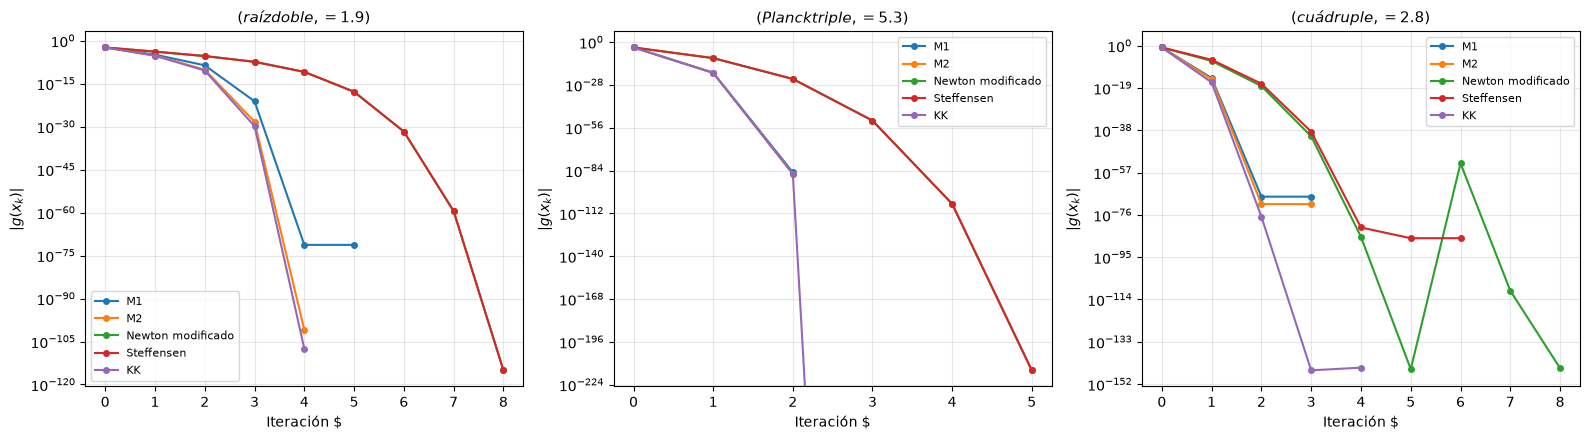

In [7]:
# ===== Gráficos de convergencia para g1, g2 y g3 =====
# Comparación visual del residuo |g(x_k)| en subgráficas (1x3)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

selected_cases = [
    (benchmarks[0], '1.9', '$ (raíz doble, =1.9$)'),
    (benchmarks[1], '5.3', '$ (Planck triple, =5.3$)'),
    (benchmarks[2], '2.8', '$ (cuádruple, =2.8$)')
]

for ax, (b, seed, title) in zip(axes, selected_cases):
    for method in methods:
        r = history[(b['id'], seed, method)]
        ys = [float(q) for q in r['residuals'] if q > 0]
        if ys:
            ax.semilogy(range(len(ys)), ys, marker='o', markersize=4, label=method)
    ax.set_xlabel('Iteración $')
    ax.set_ylabel('$|g(x_k)|$')
    ax.set_title(title, fontsize=11)
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 8. Validación Teórica vs. Experimental del ACOC (Semana 9: Newton vs. Secante)

Siguiendo la ruta pedagógica de Turner et al. (2018, Cap. 5): **Teoría $
ightarrow$ Implementación $
ightarrow$ Análisis $
ightarrow$ Aplicación**, evaluamos experimentalmente el Orden de Convergencia Computacional Aproximado (ACOC) para los métodos canónicos del curso:
* **Método de Newton estándar**: Orden teórico cuadrático ( = 2$).
* **Método de la Secante clásico**: Orden teórico superlineal ( = 
rac{1+\sqrt{5}}{2} pprox 1.618$).

Para aislar el orden asintótico puro de la multiplicidad, se prueba sobre el problema no lineal (x) = x^3 - x - 2 = 0$ (raíz simple $lpha pprox 1.5213797$) con alta precisión (150 dps) para evitar la saturación prematura por precisión finita.

--- Comparación Experimental de ACOC (Turner Cap. 5) ---
Newton estándar (Teórico p=2.000): Últimos valores ACOC = [2.0008, 2.0, 2.0]
Secante clásica (Teórico p≈1.618): Últimos valores ACOC = [1.6057, 1.6229, 1.6162]


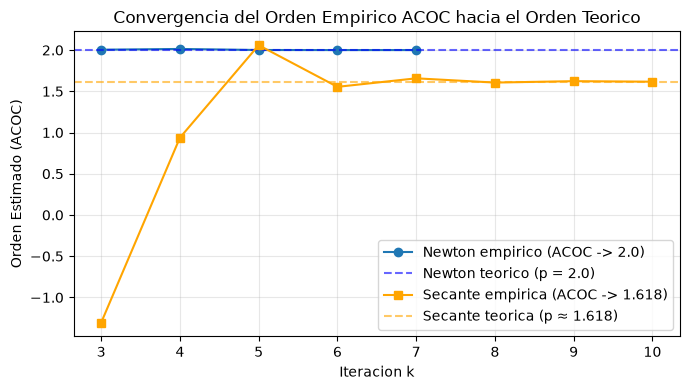

In [8]:
# ===== Validación experimental del ACOC: Newton (p=2) vs Secante (p≈1.618) =====
"""
Experimento comparativo de velocidad de convergencia y orden asintótico empírico (ACOC)
para los métodos canónicos de la Semana 9 (Turner Cap. 5).
"""
def f_test(x): return x**3 - x - 2
def df_test(x): return 3*x**2 - 1

# Newton estándar (p=2)
x_newt = mp.mpf('2.0')
xs_newt = [x_newt]
for _ in range(7):
    x_newt = x_newt - f_test(x_newt)/df_test(x_newt)
    xs_newt.append(x_newt)

# Secante clásica (p≈1.618)
x_s0 = mp.mpf('2.0'); x_s1 = mp.mpf('1.9')
xs_sec = [x_s0, x_s1]
for _ in range(9):
    f0 = f_test(xs_sec[-2]); f1 = f_test(xs_sec[-1])
    x_next = xs_sec[-1] - f1 * (xs_sec[-1] - xs_sec[-2]) / (f1 - f0)
    xs_sec.append(x_next)

def compute_acoc_history(xs):
    history = []
    for k in range(3, len(xs)):
        e1 = abs(xs[k] - xs[k-1])
        e2 = abs(xs[k-1] - xs[k-2])
        e3 = abs(xs[k-2] - xs[k-3])
        if min(e1, e2, e3) > 0 and mp.log(e2/e3) != 0:
            val = mp.log(e1/e2) / mp.log(e2/e3)
            history.append(float(val))
        else:
            history.append(np.nan)
    return history

acoc_newt = compute_acoc_history(xs_newt)
acoc_sec = compute_acoc_history(xs_sec)

print('--- Comparación Experimental de ACOC (Turner Cap. 5) ---')
print(f'Newton estándar (Teórico p=2.000): Últimos valores ACOC = {[round(v, 4) for v in acoc_newt[-3:]]}')
print(f'Secante clásica (Teórico p≈1.618): Últimos valores ACOC = {[round(v, 4) for v in acoc_sec[-3:]]}')

# Gráfica de convergencia de ACOC hacia el orden teórico
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(3, 3 + len(acoc_newt)), acoc_newt, 'o-', label='Newton empirico (ACOC -> 2.0)')
ax.axhline(2.0, color='blue', linestyle='--', alpha=0.6, label='Newton teorico (p = 2.0)')
ax.plot(range(3, 3 + len(acoc_sec)), acoc_sec, 's-', color='orange', label='Secante empirica (ACOC -> 1.618)')
ax.axhline(1.618034, color='orange', linestyle='--', alpha=0.6, label='Secante teorica (p ≈ 1.618)')
ax.set_xlabel('Iteracion k')
ax.set_ylabel('Orden Estimado (ACOC)')
ax.set_title('Convergencia del Orden Empirico ACOC hacia el Orden Teorico')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 9. Extensión a Sistemas de Ecuaciones No Lineales y Discusión Crítica

### Extensión a Sistemas de Ecuaciones No Lineales (Semana 9, Sesión 18 - Turner Cap. 5)
En el contexto multidimensional $\mathbf{F}(\mathbf{x}) = \mathbf{0}$ con $\mathbf{F}: \mathbb{R}^n 	o \mathbb{R}^n$, la derivada escalar '(x)$ se generaliza a la matriz Jacobiana $\mathbf{J}(\mathbf{x}) \in \mathbb{R}^{n 	imes n}$:
7056\mathbf{J}_{ij}(\mathbf{x}) = 
rac{\partial F_i}{\partial x_j}(\mathbf{x}).7056
El método de Newton multivariable resuelve en cada iteración el sistema lineal $\mathbf{J}(\mathbf{x}_k)\mathbf{s}_k = -\mathbf{F}(\mathbf{x}_k)$ y actualiza $\mathbf{x}_{k+1} = \mathbf{x}_k + \mathbf{s}_k$, requiriendo factorizaciones LU ((n^3)$) y ^2$ derivadas parciales. 
Los métodos libres de derivadas de orden óptimo analizados en este proyecto (como la familia de Jerezano et al., 2026) cobran especial relevancia para evitar el cómputo explícito de $\mathbf{J}(\mathbf{x})$, extendiéndose mediante aproximaciones matriciales secantes multidimensionales o variantes de Broyden.

### Discusión sobre Estabilidad, Limitaciones y Conclusiones para Ciencia de Datos
1. **Puntos Críticos y Pendientes Nulas**: Cuando '(x) pprox 0$ o la pendiente secante  = 
rac{g(w_k)-g(x_k)}{w_k-x_k} 	o 0$, el método experimenta explosión numérica. Nuestro solucionador captura explícitamente  y detiene la ejecución de manera controlada.
2. **Estancamiento Numérico ( = x_k$)**: Para métodos sin derivadas de orden superior donde  = x_k + eta g(x_k)^2$, cuando el residuo cae a la escala de la precisión de máquina, la perturbación se pierde por redondeo binario/decimal, provocando  == x_k$. El código diagnostica oportunamente este fenómeno como .
3. **Conclusión Orientada a Optimización y Ciencia de Datos**: En optimización numérica y entrenamiento de modelos, encontrar puntos críticos equivale a resolver $
abla L(\mathbf{	heta}) = \mathbf{0}$. En problemas de pérdida con autovalores nulos del Hessiano (mínimos degenerados o valles planos con multiplicidad  > 1$), los métodos de Newton estándar desaceleran a orden lineal (=1$). Comprender métodos de orden superior adaptados a multiplicidad permite acelerar el entrenamiento y evitar estancamientos en superficies de pérdida no convexas.

## Referencias

J. H. Jerezano, F. I. Chicharro y N. Garrido-Sáez, “Derivative-free optimal multiple-root finding family of iterative methods”, *Computational and Applied Mathematics*, vol. 45, art. 304, 2026. [doi:10.1007/s40314-026-03702-8](https://doi.org/10.1007/s40314-026-03702-8).

Universidad Externado de Colombia, Departamento de Matemáticas, *Guía del Proyecto Integrador: Métodos Numéricos*, 2026.